# 11 — Explaining the final model (SHAP)

**Purpose.** Open the black box of the final model — XGBoost with the settings frozen in notebook 10 — and answer: *which measurements drive each diagnosis, in which direction, and does the model treat measured and imputed values differently?* Then triangulate the answer with the two independent importance measures already in the project.

**Reads:** `../results/final_model_xgb.json` (the exact model saved by notebook 10), `final_test_predictions.csv`, `../data/processed/*`, `../data/raw/dataset.xlsx`, and, for the triangulation, `fs_importance_stability.csv` (notebook 06) and `err_per_test.csv` (notebook 12) · **Writes:** `../results/shap_*.csv`, `shap_test.npz`, `shap_*.png`

**Nothing in the model changes here.** This notebook only explains the saved model; no result of it feeds back into any choice.

## What SHAP is, in plain words

For every patient and every disease, the model produces a **score** (before it is turned into a probability). SHAP splits that score into one **contribution per measurement**: how much did this patient's ESR push the score for Rheumatoid Arthritis up or down, compared with an average patient? The contributions add up exactly to the model's score (checked in section 2), so the explanation is complete, not an approximation of the model.

* A **positive** SHAP value for a disease means the measurement pushed the model *toward* that disease; negative, *away* from it.
* **Mean |SHAP|** (average absolute contribution) measures how much the model relies on a measurement.
* Units are the model's internal log-odds scale; compare sizes, not absolute values.

## Questions and how they are answered

| # | Question | Section |
|---|---|---|
| 1 | Does the explanation exactly reproduce the model? (sanity) | 2 |
| 2 | Which measurements matter most, overall and per disease? | 3 |
| 3 | In which direction does each top measurement push each disease? | 4 |
| 4 | Do three independent importance methods agree? (SHAP, notebook 06 permutation importance, notebook 12 cost of a missing test) | 5 |
| 5 | Does the model rely less on a value when it was imputed rather than measured? | 6 |
| 6 | What does an explanation look like for single patients (a correct case, a confident error, a low-confidence case)? | 7 |
| 7 | Is the ranking stable between training and test patients? | 8 |

**Caveats (important for the paper).** (1) SHAP explains *what the model uses*, not what causes disease. (2) The dataset appears to be simulated (notebook 01b); relationships found here describe this data. (3) Correlated measurements (ESR with CRP; the antibody markers) share credit, so a low SHAP value can mean "redundant", not "irrelevant". (4) For patients whose test was missing, the model sees a **statistically imputed** value; its contribution is the contribution of that estimate (section 6).

## 0. Setup

**What this does:** imports libraries and prints versions.

In [3]:
import sys, os, json, warnings
sys.path.append('..')

import numpy as np
import pandas as pd
import shap, xgboost
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu
from xgboost import XGBClassifier
from src.evaluation.metrics import holm

print("pandas", pd.__version__, "| numpy", np.__version__, "| shap", shap.__version__, "| xgboost", xgboost.__version__)
os.makedirs('../results', exist_ok=True)

pandas 3.0.5 | numpy 2.5.2 | shap 0.52.0 | xgboost 3.4.1


## 1. Load the saved model and verify it is the model of notebook 10

**What this does:** loads the final model from disk and the preprocessed tables, then checks that the loaded model reproduces **exactly** the probabilities stored with the test predictions in notebook 10 (so we are explaining the model that was evaluated, not a re-trained lookalike). It also loads the *original-unit* values of the test patients (ESR in mm/h, RF in IU/mL, …) and which tests were missing, for readable plots and for section 6.

**Checks (all must pass):** the loaded model reproduces the stored probabilities (max difference < 1e-5); the raw test rows match the processed test patients and labels.

In [4]:
P = '../data/processed/'
X_tr = pd.read_csv(P + 'X_raw_train.csv', index_col=0)
X_te = pd.read_csv(P + 'X_raw_test.csv', index_col=0)
y_te = pd.read_csv(P + 'y_test.csv', index_col=0).iloc[:, 0].to_numpy()
with open(P + 'label_mapping.json', encoding='utf-8') as f:
    label_mapping = json.load(f)
classes = [k for k, v in sorted(label_mapping.items(), key=lambda kv: kv[1])]; K = len(classes)
feats = list(X_te.columns); F_ = len(feats)

model = XGBClassifier(); model.load_model('../results/final_model_xgb.json')
saved = pd.read_csv('../results/final_test_predictions.csv', index_col=0)
assert saved.index.equals(X_te.index) and (saved['true'].to_numpy() == y_te).all()
Pte = model.predict_proba(X_te)
diff = np.abs(Pte - saved[[f"p_{c}" for c in classes]].to_numpy()).max()
print(f"max |loaded model - stored probabilities| = {diff:.2e}")
assert diff < 1e-5
pred, conf = Pte.argmax(1), Pte.max(1)
assert (pred == saved['pred'].to_numpy()).all()

raw = pd.read_excel('../data/raw/dataset.xlsx').loc[X_te.index]
assert (raw['Disease'].map(label_mapping).to_numpy() == y_te).all()
vals = raw[feats].copy()
for c in ['HLA-B27', 'ANA', 'Anti-Ro', 'Anti-La', 'Anti-dsDNA', 'Anti-Sm']:
    vals[c] = vals[c].map({'Positive': 1, 'Negative': 0})
vals['Gender'] = vals['Gender'].map({'Male': 1, 'Female': 0})
miss = vals.isna()
tests = [c for c in feats if miss[c].any()]
print("model verified | test patients:", len(X_te), "| features:", F_, "| tests with gaps:", len(tests))

max |loaded model - stored probabilities| = 2.98e-08
model verified | test patients: 2417 | features: 14 | tests with gaps: 12


## 2. Compute SHAP values and verify additivity

**What this does:** a `TreeExplainer` computes the exact SHAP values for all 2,417 test patients, all 14 measurements and all 7 diseases (array of shape 2,417 × 14 × 7).

**Check (the key sanity test):** for every patient and disease, `base value + sum of the 14 contributions` must equal the model's raw score. The maximum error must be below 0.001. This proves the explanation is complete.

In [5]:
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(X_te)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)
base = np.asarray(explainer.expected_value).reshape(-1)
assert sv.shape == (len(X_te), F_, K) and base.shape == (K,)
margin = model.predict(X_te, output_margin=True)
err = np.abs(sv.sum(1) + base[None, :] - margin).max()
print(f"SHAP array: {sv.shape} | max additivity error = {err:.2e}")
assert err < 1e-3
print("additivity check passed")

SHAP array: (2417, 14, 7) | max additivity error = 8.11e-06
additivity check passed


## 3. Which measurements matter most?

**What this does:** for each measurement and each disease, the mean absolute SHAP value over the 2,417 test patients (how strongly the model relies on that measurement for that disease), plus the **overall** importance (average over the 7 diseases) and its rank. A heat-map is saved to `../results/shap_importance_heatmap.png`.

**How to read it:** read across a row to see which diseases a measurement helps decide; read down a column to see which measurements decide a disease. A measurement with a high overall value but concentrated in one disease is a specialist; one that is high everywhere is a generalist.

            Ankylosing Spondylitis  Normal  Psoriatic Arthritis  Reactive Arthritis  Rheumatoid Arthritis  Sjögren's Syndrome  Systemic Lupus Erythematosus  OVERALL  rank
ESR                          0.962   1.154                1.046               1.513                 0.806               1.384                         0.491    1.051     1
CRP                          1.059   0.950                0.945               1.197                 0.455               0.778                         0.456    0.834     2
RF                           0.048   1.064                1.146               0.028                 1.325               0.102                         0.060    0.539     3
Anti-CCP                     0.085   1.090                1.005               0.050                 1.326               0.138                         0.058    0.536     4
HLA-B27                      1.055   0.064                0.282               0.647                 0.304               0.012                    

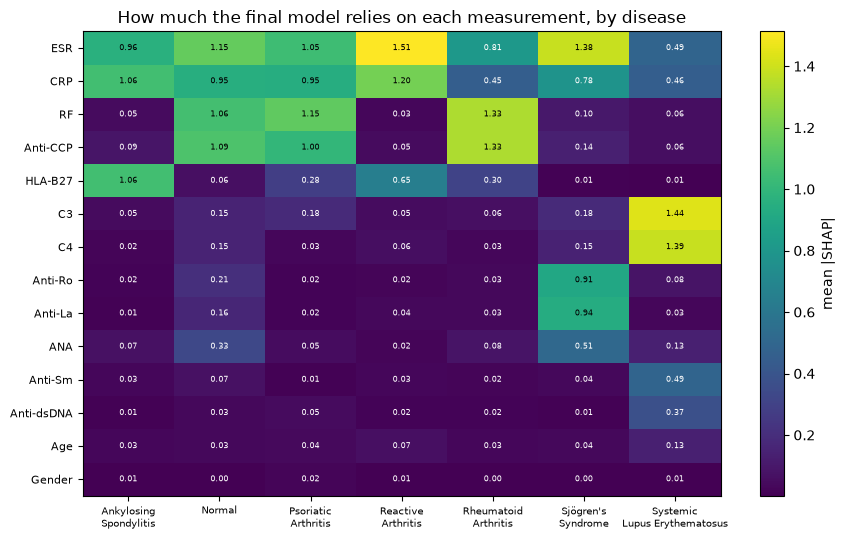

In [6]:
imp = pd.DataFrame(np.abs(sv).mean(0), index=feats, columns=classes)
imp['OVERALL'] = imp[classes].mean(axis=1)
imp['rank'] = imp['OVERALL'].rank(ascending=False).astype(int)
imp = imp.sort_values('OVERALL', ascending=False)
print(imp.round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 5.5))
M = imp[classes].to_numpy()
im = ax.imshow(M, cmap='viridis', aspect='auto')
ax.set_xticks(range(K)); ax.set_xticklabels([c.replace(' ', '\n', 1) for c in classes], fontsize=7)
ax.set_yticks(range(len(imp))); ax.set_yticklabels(imp.index, fontsize=8)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha='center', va='center', fontsize=6, color='white' if M[i, j] < M.max() * 0.6 else 'black')
plt.colorbar(im, label='mean |SHAP|'); ax.set_title('How much the final model relies on each measurement, by disease')
plt.tight_layout(); plt.savefig('../results/shap_importance_heatmap.png', dpi=150); plt.show()

## 4. Direction: does a higher value push toward or away from the disease?

**What this does:** for each disease, the five most relied-upon measurements, with the **direction**: the Spearman correlation between the patient's *measured* value (original units; imputed patients excluded) and that value's SHAP contribution to the disease.

* `rho` > +0.3: **higher value → higher score for the disease** (↑).
* `rho` < −0.3: **higher value → lower score** (↓).
* otherwise: **mixed / non-monotonic** (e.g. both a very low and a very high value push the same way).

**Why this matters:** it turns the model into readable rules (e.g. "high ESR pushes toward Rheumatoid Arthritis and away from Sjögren's"). Check the pattern against clinical expectations, keeping in mind the data is simulated.

In [7]:
rows = []
for c in range(K):
    order = np.argsort(-np.abs(sv[:, :, c]).mean(0))[:5]
    for rk, j in enumerate(order, 1):
        m = ~miss[feats[j]].to_numpy()
        rho = spearmanr(vals[feats[j]].to_numpy()[m], sv[m, j, c]).statistic if m.sum() > 10 else np.nan
        arrow = '↑ higher value raises score' if rho > 0.3 else ('↓ higher value lowers score' if rho < -0.3 else 'mixed / non-monotonic')
        rows.append({'disease': classes[c], 'rank': rk, 'measurement': feats[j], 'mean_abs_shap': np.abs(sv[:, j, c]).mean(),
                     'rho_value_vs_shap': rho, 'direction': arrow})
top5 = pd.DataFrame(rows)
for c in classes:
    print(f"\n=== {c} ===")
    print(top5[top5.disease == c].drop(columns='disease').round(3).to_string(index=False))


=== Ankylosing Spondylitis ===
 rank measurement  mean_abs_shap  rho_value_vs_shap                   direction
    1         CRP          1.059              0.816 ↑ higher value raises score
    2     HLA-B27          1.055              0.844 ↑ higher value raises score
    3         ESR          0.962              0.432 ↑ higher value raises score
    4    Anti-CCP          0.085             -0.746 ↓ higher value lowers score
    5         ANA          0.069             -0.817 ↓ higher value lowers score

=== Normal ===
 rank measurement  mean_abs_shap  rho_value_vs_shap                   direction
    1         ESR          1.154             -0.893 ↓ higher value lowers score
    2    Anti-CCP          1.090             -0.814 ↓ higher value lowers score
    3          RF          1.064             -0.748 ↓ higher value lowers score
    4         CRP          0.950             -0.861 ↓ higher value lowers score
    5         ANA          0.328             -0.835 ↓ higher value lower

## 5. Do three independent measures of importance agree?

**What this does:** compares, for the 12 tests with gaps, three different answers to "how much does the model need this measurement?":

1. **SHAP** (this notebook): mean absolute contribution (overall);
2. **Permutation importance** (notebook 06): how much macro-F1 drops when the measurement is shuffled;
3. **Cost of a missing test** (notebook 12): how much higher the error rate is for patients lacking it.

and reports the pairwise Spearman rank correlations. High agreement means the ranking is a property of the data and model, not an artefact of one method; a method that disagrees deserves a sentence in the paper.

In [8]:
tri = pd.DataFrame({'SHAP (this notebook)': imp.loc[tests, 'OVERALL']})
p06 = '../results/fs_importance_stability.csv'; p12 = '../results/err_per_test.csv'
if os.path.exists(p06):
    s = pd.read_csv(p06); s = s[s.model == 'XGBoost'].set_index('feature')['mean_importance']
    tri['permutation importance (nb 06)'] = s.reindex(tests)
if os.path.exists(p12):
    e = pd.read_csv(p12).set_index('test')['error_diff']
    tri['error cost when missing (nb 12)'] = e.reindex(tests)
print(tri.round(4).sort_values('SHAP (this notebook)', ascending=False).to_string())
if tri.shape[1] > 1:
    print("\nSpearman rank correlation between methods (12 tests):")
    print(tri.corr(method='spearman').round(2).to_string())

            SHAP (this notebook)  permutation importance (nb 06)  error cost when missing (nb 12)
ESR                       1.0509                          0.1923                           0.1317
CRP                       0.8341                          0.0336                           0.0383
RF                        0.5388                          0.0582                           0.1245
Anti-CCP                  0.5359                          0.0563                           0.0652
HLA-B27                   0.3387                          0.0523                           0.0211
C3                        0.3020                          0.0274                           0.0277
C4                        0.2603                          0.0253                           0.0245
Anti-Ro                   0.1848                          0.0300                           0.0243
Anti-La                   0.1750                          0.0305                           0.0223
ANA                 

## 6. Does the model rely less on a value when it was imputed?

**What this does:** for each of the 12 tests, compares the model's reliance on it — the absolute SHAP contribution **to the class the model predicted** — between patients where the test was **measured** and patients where it was **missing (imputed)**. `ratio` = mean for imputed ÷ mean for measured; the Mann–Whitney test (Holm-corrected over 12 tests) asks whether the two groups differ.

**How to read it:**
* `ratio` clearly **below 1**: the model leans less on imputed values — it has learned they are weaker evidence (consistent with notebook 12, where a missing test raises the error rate).
* `ratio` **close to 1**: an imputed value is used almost as strongly as a measured one. Imputed values are estimated from the *other* measurements, so the model can partly recover the information; also the imputed value carries the other tests' signal rather than new information.
* Imputed values are not random noise: a ratio near or even above 1 does **not** mean the model is "inventing" information, it means the imputed estimate sits at positions the trees split on.

In [9]:
idx = np.arange(len(pred))
rows = []
for t in tests:
    j = feats.index(t); a = np.abs(sv[idx, j, pred]); m = miss[t].to_numpy()
    p = mannwhitneyu(a[m], a[~m]).pvalue
    rows.append({'test': t, 'n_missing': int(m.sum()), 'mean_abs_shap_measured': a[~m].mean(), 'mean_abs_shap_imputed': a[m].mean(),
                 'ratio_imputed/measured': a[m].mean() / a[~m].mean(), 'p_raw': p})
imv = pd.DataFrame(rows); imv['p_holm'] = holm(imv['p_raw'])
imv = imv.sort_values('ratio_imputed/measured').reset_index(drop=True)
print(imv.drop(columns='p_raw').round(4).to_string(index=False))
if os.path.exists(p12):
    e = pd.read_csv(p12).set_index('test')['error_diff']
    r = spearmanr(1 - imv.set_index('test')['ratio_imputed/measured'], e.reindex(imv['test']))
    print(f"\nSpearman correlation, (1 - ratio) vs error cost when missing (notebook 12): rho={r.statistic:.2f}, p={r.pvalue:.3f}")

      test  n_missing  mean_abs_shap_measured  mean_abs_shap_imputed  ratio_imputed/measured  p_holm
        C4        428                  0.3875                 0.0653                  0.1686  0.0038
        C3        345                  0.3639                 0.0786                  0.2159  0.0000
   HLA-B27        379                  0.3171                 0.0927                  0.2924  0.0000
       ANA        722                  0.1672                 0.1041                  0.6224  0.0002
   Anti-Ro        583                  0.1538                 0.1025                  0.6664  0.0000
   Anti-La        631                  0.1270                 0.0886                  0.6975  0.0001
  Anti-CCP        672                  0.4112                 0.3488                  0.8481  0.0000
       CRP        492                  0.3745                 0.3184                  0.8504  0.0000
        RF        262                  0.3965                 0.3733                  0.941

> **Reading of the result above (code and outputs are unchanged).** Imputed values were used far less than measured ones for C3, C4 and HLA-B27 (ratio 0.17–0.29) but almost as strongly for ESR, RF and CRP (0.85–1.06). The link with the cost of a missing test found in notebook 12 was **not** present (Spearman ρ = −0.06, p = 0.86). Interpretation, not tested: imputation can recover ESR, RF and CRP from correlated measurements but cannot recover C3, C4 or HLA-B27; the cost of a missing test reflects how much *unique* information it carries, not how much the model leans on its imputed value.

### 6b. What the dependence looks like

**What this does:** for the four most relied-upon tests, a scatter of the measurement's value (original units) against its SHAP contribution, for the disease where that test matters most. **Filled dots = measured, open dots = imputed.** Shows the shape of the learned relationship (thresholds, plateaus) and where the imputed patients sit. Saved to `../results/shap_dependence.png`.

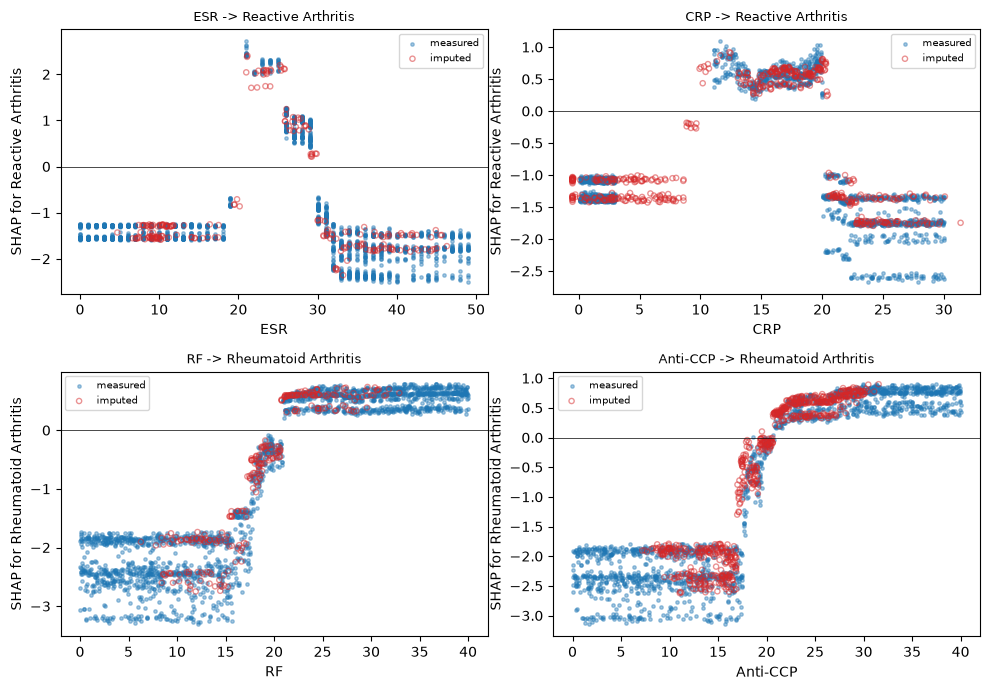

In [10]:
top4 = list(imp.index[:4])
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, f in zip(axes.ravel(), top4):
    j = feats.index(f); c = int(np.argmax(np.abs(sv[:, j, :]).mean(0)))
    x = vals[f].to_numpy(); s = sv[:, j, c]; m = miss[f].to_numpy() if f in tests else np.zeros(len(x), bool)
    ax.scatter(x[~m], s[~m], s=6, alpha=0.4, label='measured')
    if m.any():
        xi = X_te[f].to_numpy()                       # scaled imputed value; plot at the equivalent original-unit position
        mu, sd = np.nanmean(vals[f]), np.nanstd(vals[f])
        ax.scatter(xi[m] * sd + mu, s[m], s=14, facecolors='none', edgecolors='tab:red', alpha=0.5, label='imputed')
    ax.axhline(0, color='k', lw=0.5); ax.set_xlabel(f); ax.set_ylabel(f'SHAP for {classes[c][:22]}'); ax.set_title(f"{f} -> {classes[c]}", fontsize=9)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('../results/shap_dependence.png', dpi=150); plt.show()

### 6c. Beeswarm plots for the two hardest diseases

**What this does:** SHAP's standard summary plot for Ankylosing Spondylitis and Reactive Arthritis. One row per measurement, one dot per patient; position = contribution to that disease; colour = the measurement's (scaled) value (red high, blue low). Shows at a glance which measurements push these two diseases up or down and how consistently. Saved to `../results/shap_beeswarm_*.png`.

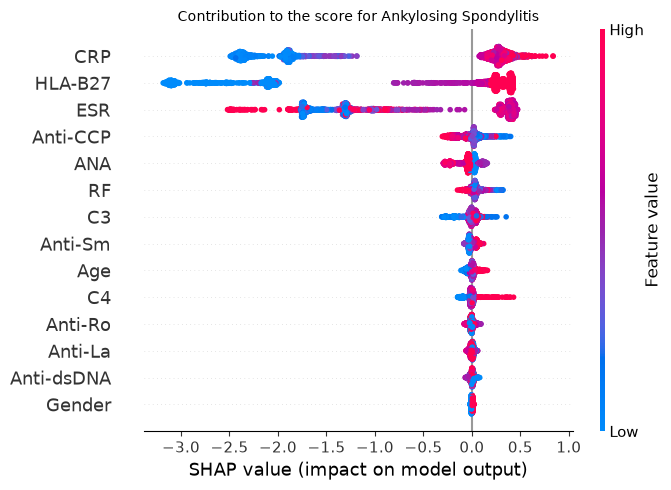

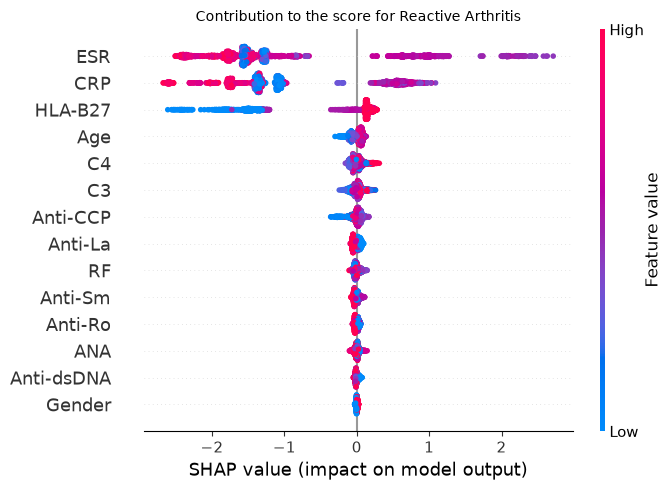

In [11]:
for cname in ('Ankylosing Spondylitis', 'Reactive Arthritis'):
    c = classes.index(cname)
    plt.figure(figsize=(7, 5))
    shap.summary_plot(sv[:, :, c], X_te, feature_names=feats, show=False, max_display=14, plot_size=None)
    plt.title(f"Contribution to the score for {cname}", fontsize=10); plt.tight_layout()
    plt.savefig(f"../results/shap_beeswarm_{cname.split()[0]}.png", dpi=150); plt.show()

## 7. Three individual patients (selected by rule, not by looks)

**What this does:** explains three test patients chosen by rules fixed here so the selection cannot be cherry-picked:
* **A — a typical correct case:** a Ankylosing Spondylitis patient classified correctly, whose confidence is closest to the median confidence of such patients.
* **B — a confident error:** the Ankylosing Spondylitis patient who was misclassified as Rheumatoid Arthritis with the **highest** confidence (the most instructive failure).
* **C — a low-confidence case:** the misclassified patient (any disease) with the **lowest** confidence — the kind the deferral rule would hand to a specialist.

For each, the 8 largest contributions are shown twice: for the **class the model predicted** and for the **true class**. Labels show the patient's original-unit value, or `missing (imputed)`. Red bars push toward the class, blue away. Saved to `../results/shap_patients.png`.

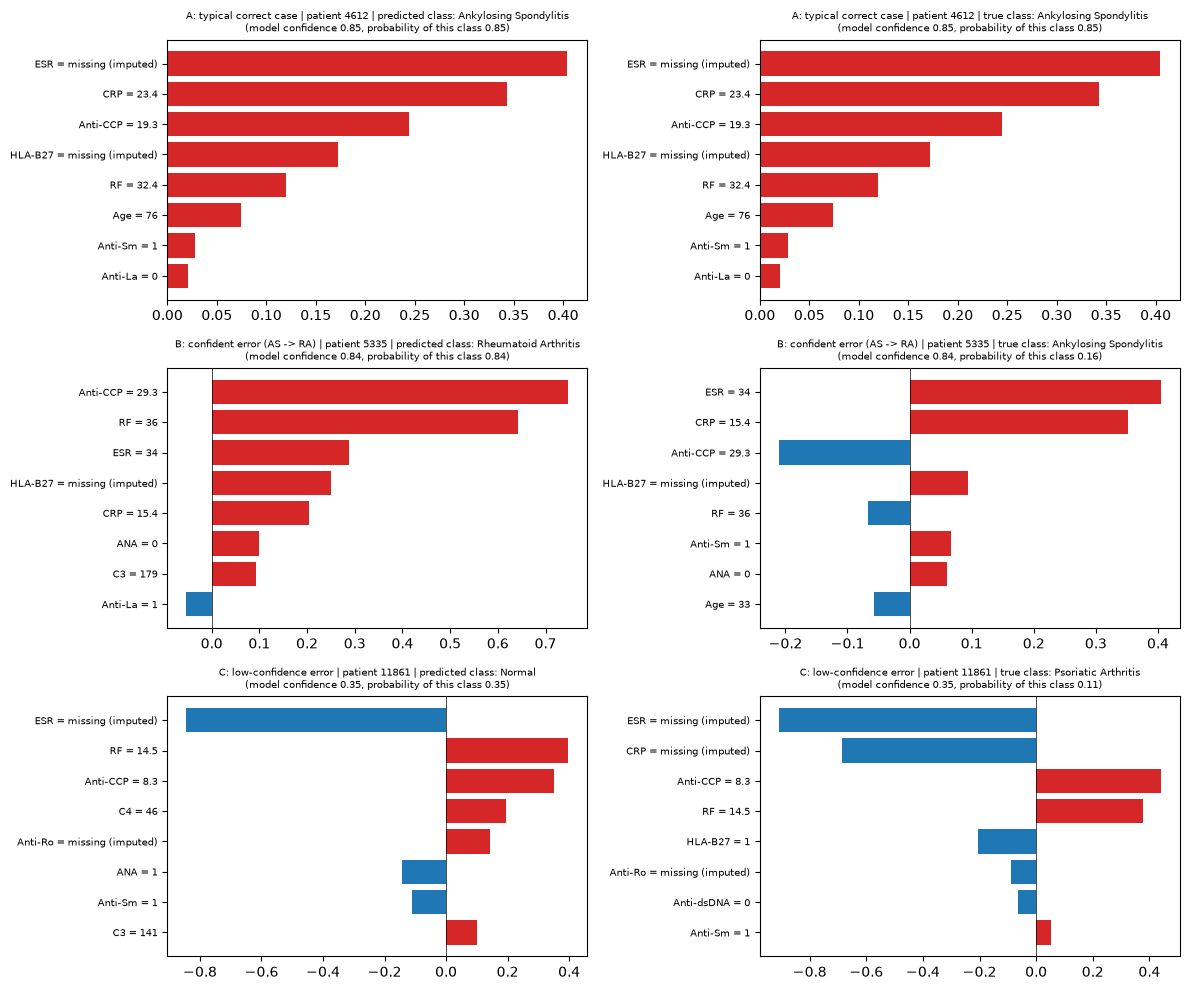

A: typical correct case: patient 4612, true = Ankylosing Spondylitis, predicted = Ankylosing Spondylitis, confidence 0.853, tests missing: 3
B: confident error (AS -> RA): patient 5335, true = Ankylosing Spondylitis, predicted = Rheumatoid Arthritis, confidence 0.841, tests missing: 3
C: low-confidence error: patient 11861, true = Psoriatic Arthritis, predicted = Normal, confidence 0.350, tests missing: 4


In [12]:
AS_i, RA_i = classes.index('Ankylosing Spondylitis'), classes.index('Rheumatoid Arthritis')
ca = np.where((y_te == AS_i) & (pred == AS_i))[0]; a_i = ca[np.argmin(np.abs(conf[ca] - np.median(conf[ca])))]
cb = np.where((y_te == AS_i) & (pred == RA_i))[0]; b_i = cb[np.argmax(conf[cb])]
cc = np.where(pred != y_te)[0];                    c_i = cc[np.argmin(conf[cc])]
cases = [('A: typical correct case', a_i), ('B: confident error (AS -> RA)', b_i), ('C: low-confidence error', c_i)]

def lab(i, j):
    if miss.iloc[i, j]: return f"{feats[j]} = missing (imputed)"
    v = vals.iloc[i, j]; return f"{feats[j]} = {v:.0f}" if float(v).is_integer() else f"{feats[j]} = {v:.1f}"

fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for r, (title, i) in enumerate(cases):
    for col, (cls, kind) in enumerate(((pred[i], 'predicted'), (y_te[i], 'true'))):
        s = sv[i, :, cls]; o = np.argsort(-np.abs(s))[:8][::-1]
        axes[r, col].barh(range(8), s[o], color=['tab:red' if v > 0 else 'tab:blue' for v in s[o]])
        axes[r, col].set_yticks(range(8)); axes[r, col].set_yticklabels([lab(i, j) for j in o], fontsize=7)
        axes[r, col].axvline(0, color='k', lw=0.5)
        axes[r, col].set_title(f"{title} | patient {X_te.index[i]} | {kind} class: {classes[cls]}\n(model confidence {conf[i]:.2f}, probability of this class {Pte[i, cls]:.2f})", fontsize=7)
plt.tight_layout(); plt.savefig('../results/shap_patients.png', dpi=150); plt.show()
for title, i in cases:
    print(f"{title}: patient {X_te.index[i]}, true = {classes[y_te[i]]}, predicted = {classes[pred[i]]}, confidence {conf[i]:.3f}, tests missing: {int(miss.iloc[i].sum())}")

## 8. Is the ranking stable? (training sample vs test set)

**What this does:** recomputes the overall importance on a random sample of 2,000 **training** patients and correlates the ranking with the test ranking (Spearman), and compares the top-5 sets. A model that explains itself consistently should rank its measurements the same way on any sample of patients.

**Note:** the model was trained on these training patients, so their SHAP values describe in-sample behaviour; stability is nonetheless a useful check that the test ranking is not a quirk of 2,417 patients.

In [13]:
samp = np.random.default_rng(0).choice(len(X_tr), 2000, replace=False)
sv_tr = explainer.shap_values(X_tr.iloc[samp]); sv_tr = np.stack(sv_tr, axis=-1) if isinstance(sv_tr, list) else np.asarray(sv_tr)
imp_tr = pd.Series(np.abs(sv_tr).mean(0).mean(1), index=feats)
r = spearmanr(imp_tr[imp.index], imp['OVERALL'])
t5_te, t5_tr = set(imp.index[:5]), set(imp_tr.sort_values(ascending=False).index[:5])
print(f"Spearman correlation of overall importance, training sample vs test: {r.statistic:.3f} (p={r.pvalue:.4f})")
print("top-5 on test:", sorted(t5_te)); print("top-5 on training sample:", sorted(t5_tr)); print("same top-5 set:", t5_te == t5_tr)

Spearman correlation of overall importance, training sample vs test: 1.000 (p=0.0000)
top-5 on test: ['Anti-CCP', 'CRP', 'ESR', 'HLA-B27', 'RF']
top-5 on training sample: ['Anti-CCP', 'CRP', 'ESR', 'HLA-B27', 'RF']
same top-5 set: True


## 9. Save the results

**What this does:** writes the tables and the SHAP values (float32) to `../results/` for the paper and for any later figure.

In [14]:
imp.to_csv('../results/shap_importance_by_class.csv')
top5.to_csv('../results/shap_top5_by_class.csv', index=False)
imv.drop(columns='p_raw').to_csv('../results/shap_imputed_vs_measured.csv', index=False)
tri.to_csv('../results/shap_triangulation.csv')
np.savez_compressed('../results/shap_test.npz', shap=sv.astype(np.float32), base=base, features=np.array(feats), classes=np.array(classes), index=X_te.index.to_numpy())
print(sorted(f for f in os.listdir('../results') if f.startswith('shap')))

['shap_beeswarm_Ankylosing.png', 'shap_beeswarm_Reactive.png', 'shap_dependence.png', 'shap_importance_by_class.csv', 'shap_importance_heatmap.png', 'shap_imputed_vs_measured.csv', 'shap_patients.png', 'shap_test.npz', 'shap_top5_by_class.csv', 'shap_triangulation.csv']


## Summary — what this notebook establishes

* An exact, verified decomposition of the final model's scores into per-measurement contributions (section 2).
* Which measurements drive each diagnosis and in which direction (sections 3–4), checked against two independent importance measures (section 5).
* Whether imputed values are used less than measured ones (section 6) and what individual explanations look like, including a confident error (section 7).
* After this notebook the analysis is complete; the remaining work is writing the paper.